# AI-Powered Intelligent Trade Settlement Failure Prediction and Explainable Risk Management System

### UC Berkeley Professional Certificate in Machine Learning & Artificial Intelligence — Capstone Project

**Notebook:** `UC_Berkeley_Capstone_AI_Trade_Failure_Final.ipynb`

---

## Executive Summary

Financial institutions process large volumes of securities transactions every day. After execution, a trade must pass through a sequence of post-trade processes such as enrichment, allocation, confirmation/affirmation, matching, clearing, settlement-instruction validation, funding, inventory availability, and final settlement.

A **settlement failure** occurs when a transaction does not settle successfully on its expected settlement date. Failures may be associated with missing or changed settlement instructions, late confirmation, counterparty behavior, insufficient securities, operational mismatches, unusual trade sizes, market-calendar conditions, or other exceptions.

This capstone develops an **end-to-end AI/ML decision-support framework** that attempts to identify trades at elevated risk of settlement failure *before* settlement occurs. The project intentionally goes beyond one classifier and demonstrates a broad machine-learning lifecycle:

- Exploratory data analysis and statistical investigation
- Domain-driven feature engineering
- Leakage-safe temporal validation
- Regression
- Logistic Regression
- K-Nearest Neighbors
- Decision Trees
- Random Forest
- Support Vector Machines
- PCA and SVD
- K-Means clustering
- Isolation Forest anomaly detection
- XGBoost
- CatBoost
- Threshold and business-cost optimization
- Explainable AI using SHAP
- NLP using TF-IDF
- A grounded Generative-AI narrative layer
- Model/data-drift monitoring
- Business recommendations and responsible-AI considerations

> **Important academic note:** The trade-level data in this notebook are synthetic. The dataset was designed to reproduce plausible post-trade relationships without exposing confidential institutional data. Results therefore demonstrate methodology and should not be interpreted as production performance or actual financial-industry failure rates.

## Notebook Roadmap

1. Business understanding
2. Problem statement and research questions
3. Environment and reproducibility
4. Dataset loading and validation
5. Data dictionary and leakage controls
6. Exploratory data analysis
7. Statistical investigation
8. Feature engineering
9. Temporal train/validation/test split
10. Evaluation framework
11. Regression: settlement delay
12. Logistic Regression
13. K-Nearest Neighbors
14. Decision Tree
15. Random Forest
16. Support Vector Machine
17. PCA and SVD
18. K-Means clustering
19. Isolation Forest
20. XGBoost
21. CatBoost
22. Consolidated model comparison
23. Threshold optimization
24. Business-cost optimization
25. SHAP explainability
26. NLP failure-reason classification
27. Grounded GenAI explanation layer
28. High-risk operations queue
29. Drift monitoring
30. Final findings, recommendations, limitations, and future work

# 1. Business Understanding

A simplified securities trade lifecycle is:

**Trade Execution → Capture → Enrichment → Allocation → Confirmation/Affirmation → Matching → Clearing → Settlement Instructions → Funding/Securities Availability → Settlement**

The desired outcome is **SETTLED**. A trade may instead become **FAILED** or enter an exception state.

### Why settlement failures matter

Potential consequences include:

- Additional operations effort and exception-management cost
- Liquidity and funding pressure
- Counterparty and market exposure
- Failed-delivery charges or other economic costs
- Reduced straight-through-processing efficiency
- Regulatory and control concerns
- Client-service and reputational impact

### Proposed AI/ML objective

Instead of waiting until settlement fails, estimate a **pre-settlement failure probability** for every trade and prioritize operational intervention.

The design is **human-in-the-loop**: ML prioritizes risk; operations personnel make the final decision and take action.

# 2. Problem Statement and Research Questions

## Primary problem statement

> **Can machine learning identify trades at elevated risk of settlement failure early enough for operations teams to intervene before settlement?**

### Primary target

`settlement_failed`

- `0` = settled successfully
- `1` = failed settlement

### Assumed prediction point

Predictions are conceptually generated **before final settlement outcome is known**. Only features that would be known before that point are permitted in the predictive model.

## Research Questions

**RQ1.** Can trade characteristics predict settlement failure better than a simple baseline?  
**RQ2.** Does historical counterparty behavior improve predictive performance?  
**RQ3.** Are SSI, confirmation, matching, inventory, and timing variables strong failure indicators?  
**RQ4.** Which supervised model provides the best balance of recall, precision, PR-AUC, and operational practicality?  
**RQ5.** Can PCA reduce dimensionality while preserving useful information?  
**RQ6.** Can K-Means discover meaningful transaction-risk segments?  
**RQ7.** Can anomaly detection surface unusual transactions outside known failure patterns?  
**RQ8.** Can explainable AI identify global and trade-specific risk drivers?  
**RQ9.** Can NLP categorize post-event failure descriptions for operational analytics?  
**RQ10.** Can model thresholds be optimized according to business cost rather than an arbitrary 0.50 cutoff?

# 3. Environment, Libraries, and Reproducibility

The notebook uses a fixed `RANDOM_STATE = 42` where applicable so that experiments can be reproduced.

> **Submission note:** Before final submission, run the notebook top-to-bottom in a clean environment and retain the outputs. If a library is not installed, install it from `requirements.txt` in the starter kit.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, IsolationForest
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# 4. Dataset Loading and Initial Validation

The supplied synthetic dataset contains trade-level observations spanning trade attributes, counterparty history, settlement processing, market conditions, pre-settlement notes, and final outcomes.

The code below searches expected locations so the notebook works both inside the starter-kit folder and when downloaded separately.

In [2]:
DATA_CANDIDATES = [
    Path("../data/trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]

DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not locate trade_settlement_synthetic.csv. "
        "Place it in ../data/, ./data/, or update DATA_CANDIDATES."
    )

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["trade_date", "settlement_date"]
).sort_values("trade_date").reset_index(drop=True)

print(f"Dataset: {DATA_PATH}")
print(f"Shape: {df.shape}")
display(df.head())

Dataset: ..\data\trade_settlement_synthetic.csv
Shape: (25000, 37)


,trade_id,trade_date,settlement_date,asset_class,buy_sell,currency,market,settlement_location,counterparty_id,custodian,trade_amount,quantity,settlement_days,cross_border,month_end,quarter_end,market_holiday_mismatch,ssi_status,confirmation_delay_minutes,allocation_delay_minutes,affirmation_delay_minutes,matching_attempts,trade_amendments,hours_until_cutoff,prior_fail_rate_30d,prior_fail_rate_90d,prior_trade_count_30d,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,counterparty_avg_trade_amount,trade_size_ratio,pre_settlement_note,settlement_failed,settlement_delay_hours,failure_reason,failure_reason_description
0,TRD0001488,2023-01-02,2023-01-04,ETF,BUY,CAD,EU,JASDEC,CP074,CUST04,"178,737.3600",1696,2,0,0,0,0,VALID,90.5400,29.5200,7.6800,1,1,23.9400,0.0719,0.0747,137,0.4493,22.7400,0,"1,997,496.4800",0.0895,late confirmation,0,0.0400,SETTLED,Trade settled successfully with no final excep...
1,TRD0024982,2023-01-02,2023-01-03,Equity,BUY,USD,US,DTC,CP011,CUST03,"581,503.1800",11198,1,0,0,0,0,VALID,6.4800,6.5700,10.0200,2,0,24.0500,0.1061,0.0776,132,0.6673,22.8200,0,"2,246,662.4200",0.2588,normal pre-settlement processing,0,0.0500,SETTLED,Trade settled successfully with no final excep...
2,TRD0023819,2023-01-02,2023-01-04,Corporate Bond,BUY,CAD,UK,CREST,CP010,CUST06,"3,173,643.7400",34485,2,0,0,0,0,VALID,29.3000,9.2600,34.8900,1,0,11.8500,0.1461,0.1449,116,0.4417,21.4400,0,"59,180.7000",40.0000,counterparty recent fail rate elevated,0,0.5600,SETTLED,Trade settled successfully with no final excep...
3,TRD0021997,2023-01-02,2023-01-03,Equity,SELL,EUR,CA,CDS,CP061,CUST01,"1,217,461.7000",17388,1,1,0,0,0,VALID,9.8900,10.1800,12.5300,1,0,34.8400,0.1352,0.0983,141,0.5992,32.3900,0,"2,479,677.2500",0.4910,counterparty recent fail rate elevated,0,0.0000,SETTLED,Trade settled successfully with no final excep...
4,TRD0021840,2023-01-02,2023-01-04,Equity,BUY,USD,US,DTC,CP006,CUST07,"14,571,264.5400",187147,2,1,0,0,0,VALID,20.0000,32.0500,11.2000,2,0,6.8100,0.1134,0.0838,121,0.8685,23.0600,0,"405,203.0800",35.9604,normal pre-settlement processing,0,0.6900,SETTLED,Trade settled successfully with no final excep...


In [3]:
print("Column count:", len(df.columns))
print("\nMissing values:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

print("\nDuplicate trade IDs:", df["trade_id"].duplicated().sum())
print("Date range:", df["trade_date"].min().date(), "to", df["trade_date"].max().date())

Column count: 37

Missing values:


,missing_count



Duplicate trade IDs: 0
Date range: 2023-01-02 to 2025-11-28


# 5. Data Dictionary and Data-Leakage Controls

A high-performing model is not useful if it learns from information that would only exist **after** settlement. This project therefore separates pre-prediction features from post-outcome fields.

### Legitimate pre-settlement information

- Asset class, market, currency, trade amount
- Counterparty and custodian
- Settlement cycle and cross-border indicator
- SSI status
- Confirmation/allocation/affirmation delays
- Matching attempts and amendments
- Historical counterparty failure rates
- Liquidity, volatility, and inventory indicators

### Post-outcome / leakage fields

- `settlement_failed` — target
- `settlement_delay_hours` — realized outcome measure
- `failure_reason`
- `failure_reason_description`

The final two fields are retained only for **post-event NLP analysis**, not for pre-settlement failure prediction.

In [4]:
TARGET = "settlement_failed"

PRE_PREDICTION_FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes", "matching_attempts",
    "trade_amendments", "hours_until_cutoff", "prior_fail_rate_30d",
    "prior_fail_rate_90d", "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio"
]

LEAKAGE_COLUMNS = [
    "settlement_failed",
    "settlement_delay_hours",
    "failure_reason",
    "failure_reason_description"
]

print("Predictive feature count:", len(PRE_PREDICTION_FEATURES))
print("Leakage/post-outcome fields:", LEAKAGE_COLUMNS)

assert TARGET not in PRE_PREDICTION_FEATURES
assert not set(LEAKAGE_COLUMNS).intersection(PRE_PREDICTION_FEATURES)

Predictive feature count: 29
Leakage/post-outcome fields: ['settlement_failed', 'settlement_delay_hours', 'failure_reason', 'failure_reason_description']


### Leakage principle

A rolling feature such as `prior_fail_rate_30d` is valid only if it is calculated from **historical trades available before the current prediction**. In production, this requirement should be enforced through time-aware feature pipelines or a feature store.

# 6. Exploratory Data Analysis

The EDA is organized around business questions. Each plot should answer a specific question rather than simply visualize every column.

## 6.1 How imbalanced is settlement failure?

If failures are rare, **accuracy can be misleading**. A model that predicts every trade as settled could achieve very high accuracy while providing no business value.

,count,rate
settlement_failed,,
Settled,24511,0.9804
Failed,489,0.0196


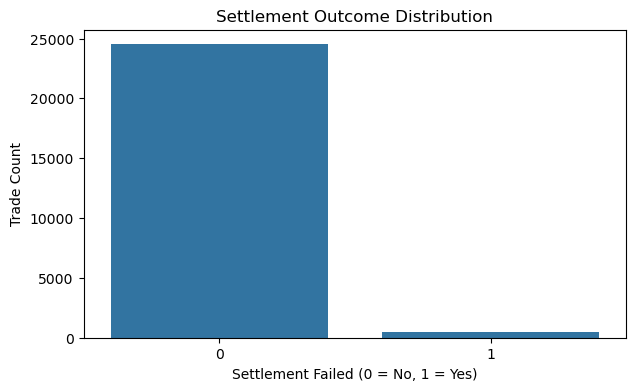

Observed synthetic failure rate: 1.96%


In [5]:
target_counts = df[TARGET].value_counts().sort_index()
target_rates = df[TARGET].value_counts(normalize=True).sort_index()

display(pd.DataFrame({
    "count": target_counts,
    "rate": target_rates
}).rename(index={0: "Settled", 1: "Failed"}))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Settlement Outcome Distribution")
plt.xlabel("Settlement Failed (0 = No, 1 = Yes)")
plt.ylabel("Trade Count")
plt.show()

failure_rate = df[TARGET].mean()
print(f"Observed synthetic failure rate: {failure_rate:.2%}")

**Interpretation:** Because the positive class is rare, primary evaluation should focus on **recall, precision, F1, ROC-AUC, and especially PR-AUC**, rather than accuracy alone.

## 6.2 Failure rate by asset class

,mean,count
asset_class,,
ETF,0.0211,2991
Equity,0.0197,10669
Government Bond,0.0191,4616
Corporate Bond,0.0190,6724


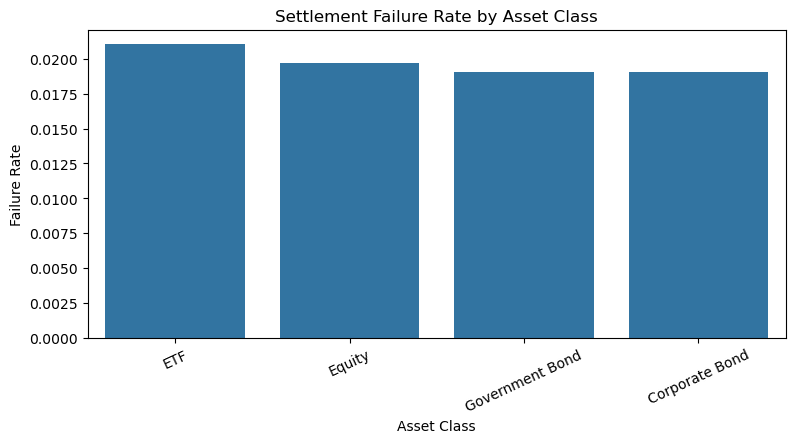

In [6]:
asset_failure = (
    df.groupby("asset_class")[TARGET]
      .agg(["mean", "count"])
      .sort_values("mean", ascending=False)
)
display(asset_failure)

plt.figure(figsize=(9, 4))
sns.barplot(data=asset_failure.reset_index(), x="asset_class", y="mean")
plt.title("Settlement Failure Rate by Asset Class")
plt.ylabel("Failure Rate")
plt.xlabel("Asset Class")
plt.xticks(rotation=25)
plt.show()

## 6.3 Failure rate by SSI status

,mean,count
ssi_status,,
MISSING,0.1375,618
CHANGED,0.0449,1315
VALID,0.0150,23067


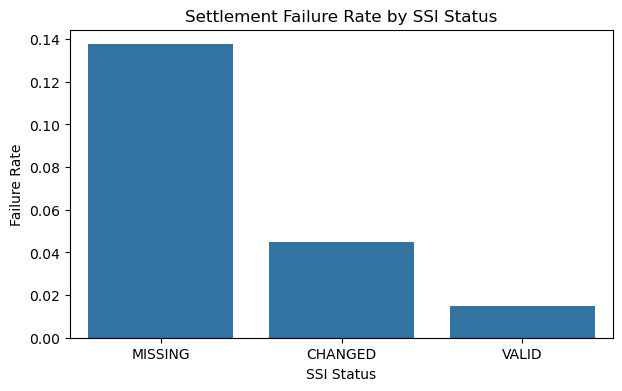

In [7]:
ssi_failure = df.groupby("ssi_status")[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False)
display(ssi_failure)

plt.figure(figsize=(7, 4))
sns.barplot(data=ssi_failure.reset_index(), x="ssi_status", y="mean")
plt.title("Settlement Failure Rate by SSI Status")
plt.ylabel("Failure Rate")
plt.xlabel("SSI Status")
plt.show()

## 6.4 Confirmation delay vs. settlement outcome

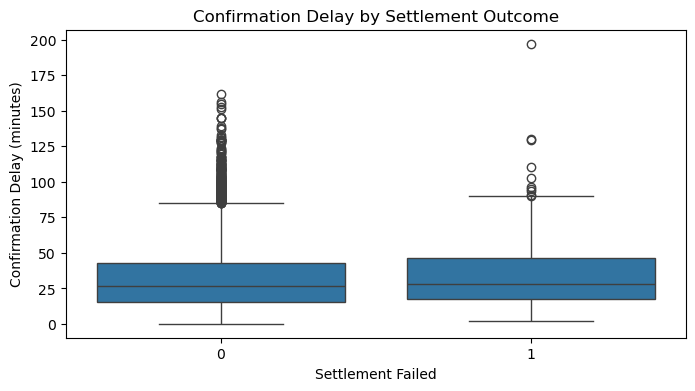

,median,mean,std,count
settlement_failed,,,,
Settled,26.7300,31.8834,22.4571,24511
Failed,29.5700,36.8005,28.8901,489


In [8]:
sample_for_plot = df.sample(min(8000, len(df)), random_state=RANDOM_STATE)

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=sample_for_plot,
    x=TARGET,
    y="confirmation_delay_minutes"
)
plt.title("Confirmation Delay by Settlement Outcome")
plt.xlabel("Settlement Failed")
plt.ylabel("Confirmation Delay (minutes)")
plt.show()

display(
    df.groupby(TARGET)["confirmation_delay_minutes"]
      .agg(["median", "mean", "std", "count"])
      .rename(index={0: "Settled", 1: "Failed"})
)

## 6.5 Historical counterparty risk vs. outcome

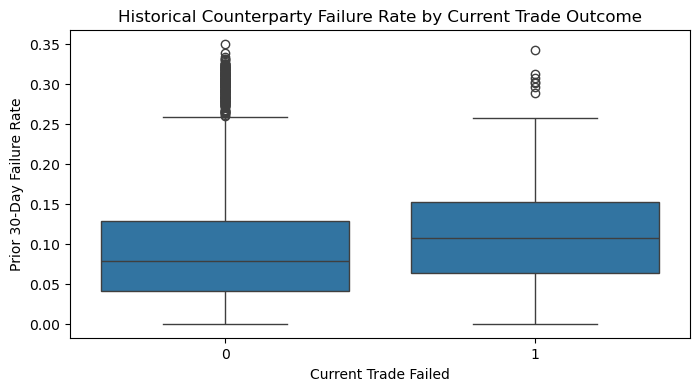

In [9]:
plt.figure(figsize=(8, 4))
sns.boxplot(
    data=sample_for_plot,
    x=TARGET,
    y="prior_fail_rate_30d"
)
plt.title("Historical Counterparty Failure Rate by Current Trade Outcome")
plt.xlabel("Current Trade Failed")
plt.ylabel("Prior 30-Day Failure Rate")
plt.show()

## 6.6 Trade-size ratio and inventory shortfall

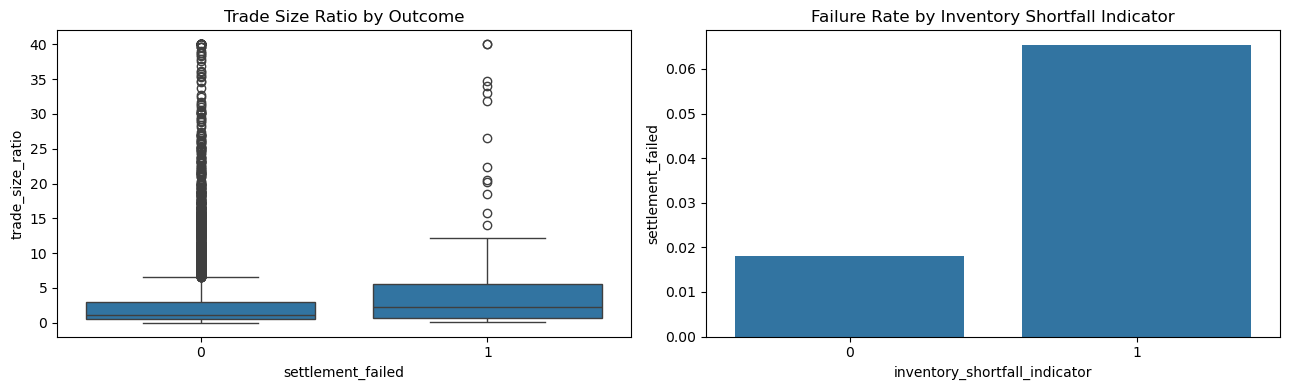

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(
    data=sample_for_plot,
    x=TARGET, y="trade_size_ratio", ax=axes[0]
)
axes[0].set_title("Trade Size Ratio by Outcome")

inv = df.groupby("inventory_shortfall_indicator")[TARGET].mean().reset_index()
sns.barplot(data=inv, x="inventory_shortfall_indicator", y=TARGET, ax=axes[1])
axes[1].set_title("Failure Rate by Inventory Shortfall Indicator")

plt.tight_layout()
plt.show()

## 6.7 Failure rate by market and cross-border status

,market,cross_border,mean,count
0,CA,0,0.0168,1371
1,CA,1,0.0304,428
2,EU,0,0.0161,2477
3,EU,1,0.0306,718
4,JP,0,0.0193,1656
5,JP,1,0.0303,528
6,UK,0,0.0196,2138
7,UK,1,0.0284,703
8,US,0,0.0158,11480
9,US,1,0.0286,3501


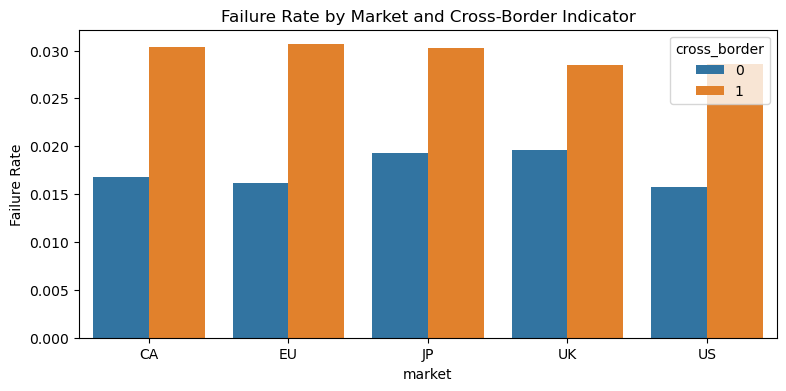

In [11]:
market_cross = (
    df.groupby(["market", "cross_border"])[TARGET]
      .agg(["mean", "count"])
      .reset_index()
)
display(market_cross)

plt.figure(figsize=(9, 4))
sns.barplot(data=market_cross, x="market", y="mean", hue="cross_border")
plt.title("Failure Rate by Market and Cross-Border Indicator")
plt.ylabel("Failure Rate")
plt.show()

# 7. Statistical Investigation

Statistical significance does **not** prove causality.

## 7.1 Chi-square test: SSI status and settlement failure

- **H0:** SSI status and settlement outcome are independent.
- **H1:** SSI status and settlement outcome are associated.

In [12]:
ssi_table = pd.crosstab(df["ssi_status"], df[TARGET])
chi2, p_value, dof, expected = chi2_contingency(ssi_table)

display(ssi_table)
print(f"Chi-square statistic: {chi2:,.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6g}")
print("Decision at alpha=0.05:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")

settlement_failed,0,1
ssi_status,,
CHANGED,1256,59
MISSING,533,85
VALID,22722,345


Chi-square statistic: 517.964
Degrees of freedom: 2
p-value: 3.35305e-113
Decision at alpha=0.05: Reject H0


## 7.2 Mann-Whitney U test: confirmation delay

- **H0:** Failed and settled trades have the same confirmation-delay distribution.
- **H1:** Their distributions differ.

In [13]:
settled_delay = df.loc[df[TARGET] == 0, "confirmation_delay_minutes"]
failed_delay = df.loc[df[TARGET] == 1, "confirmation_delay_minutes"]

u_stat, p_value = mannwhitneyu(
    failed_delay,
    settled_delay,
    alternative="two-sided"
)

print(f"Mann-Whitney U statistic: {u_stat:,.0f}")
print(f"p-value: {p_value:.6g}")
print("Decision at alpha=0.05:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")

Mann-Whitney U statistic: 6,428,347
p-value: 0.00586343
Decision at alpha=0.05: Reject H0


# 8. Domain-Driven Feature Engineering

Additional features illustrate how raw trade facts can be converted into operational-risk signals:

- `log_trade_amount`
- `confirmation_delay_log`
- `processing_delay_total`
- `operational_touch_count`
- `counterparty_risk_gap`
- `cutoff_pressure`

In [14]:
df_model = df.copy()

df_model["log_trade_amount"] = np.log1p(df_model["trade_amount"])
df_model["confirmation_delay_log"] = np.log1p(df_model["confirmation_delay_minutes"])
df_model["processing_delay_total"] = (
    df_model["confirmation_delay_minutes"] +
    df_model["allocation_delay_minutes"] +
    df_model["affirmation_delay_minutes"]
)
df_model["operational_touch_count"] = (
    df_model["matching_attempts"] + df_model["trade_amendments"]
)
df_model["counterparty_risk_gap"] = (
    df_model["prior_fail_rate_30d"] - df_model["prior_fail_rate_90d"]
)
df_model["cutoff_pressure"] = (df_model["hours_until_cutoff"] < 8).astype(int)

ENGINEERED_FEATURES = [
    "log_trade_amount",
    "confirmation_delay_log",
    "processing_delay_total",
    "operational_touch_count",
    "counterparty_risk_gap",
    "cutoff_pressure",
]

MODEL_FEATURES = PRE_PREDICTION_FEATURES + ENGINEERED_FEATURES

display(df_model[ENGINEERED_FEATURES].head())
print("Final model feature count:", len(MODEL_FEATURES))

,log_trade_amount,confirmation_delay_log,processing_delay_total,operational_touch_count,counterparty_risk_gap,cutoff_pressure
0,12.0937,4.5168,127.7400,2,-0.0028,0
1,13.2734,2.0122,23.0700,2,0.0285,0
2,14.9704,3.4111,73.4500,1,0.0012,0
3,14.0123,2.3878,32.6000,1,0.0369,0
4,16.4946,3.0445,63.2500,2,0.0296,1


Final model feature count: 35


# 9. Temporal Train / Validation / Test Split

Observations are sorted by `trade_date` and split chronologically:

- **70% Training**
- **15% Validation**
- **15% Test**

The temporal split better simulates training on the past and predicting the future.

In [15]:
n = len(df_model)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train_df = df_model.iloc[:train_end].copy()
valid_df = df_model.iloc[train_end:valid_end].copy()
test_df  = df_model.iloc[valid_end:].copy()

X_train = train_df[MODEL_FEATURES].copy()
y_train = train_df[TARGET].astype(int).copy()

X_valid = valid_df[MODEL_FEATURES].copy()
y_valid = valid_df[TARGET].astype(int).copy()

X_test = test_df[MODEL_FEATURES].copy()
y_test = test_df[TARGET].astype(int).copy()

split_summary = pd.DataFrame({
    "rows": [len(train_df), len(valid_df), len(test_df)],
    "failure_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
    "start_date": [
        train_df["trade_date"].min(),
        valid_df["trade_date"].min(),
        test_df["trade_date"].min()
    ],
    "end_date": [
        train_df["trade_date"].max(),
        valid_df["trade_date"].max(),
        test_df["trade_date"].max()
    ],
}, index=["Train", "Validation", "Test"])

display(split_summary)

,rows,failure_rate,start_date,end_date
Train,17500,0.0194,2023-01-02,2025-01-13
Validation,3750,0.0205,2025-01-13,2025-06-19
Test,3750,0.0195,2025-06-19,2025-11-28


# 10. Preprocessing and Evaluation Framework

Numeric features are scaled when the algorithm is sensitive to feature magnitude. Categorical features are one-hot encoded.

Primary rare-event metrics:

- Precision
- Recall
- F1
- ROC-AUC
- PR-AUC

In [16]:
def build_preprocessor(X, scale_numeric=True):
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_transform = StandardScaler() if scale_numeric else "passthrough"

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transform, numeric_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical_cols),
        ]
    )

def make_pipeline(estimator, X, scale_numeric=True):
    return Pipeline([
        ("preprocessor", build_preprocessor(X, scale_numeric=scale_numeric)),
        ("model", estimator),
    ])

def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def evaluate_classifier(model, X, y, label, threshold=0.50, show_plots=True):
    scores = get_scores(model, X)
    pred = (scores >= threshold).astype(int)

    metrics = {
        "model": label,
        "threshold": threshold,
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, scores),
        "pr_auc": average_precision_score(y, scores),
    }

    print(label)
    print("=" * len(label))
    print(classification_report(y, pred, digits=3, zero_division=0))
    display(pd.DataFrame([metrics]))

    if show_plots:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        ConfusionMatrixDisplay.from_predictions(y, pred, ax=axes[0], colorbar=False)
        axes[0].set_title(f"{label}: Confusion Matrix")
        RocCurveDisplay.from_predictions(y, scores, ax=axes[1])
        axes[1].set_title(f"{label}: ROC Curve")
        PrecisionRecallDisplay.from_predictions(y, scores, ax=axes[2])
        axes[2].set_title(f"{label}: Precision-Recall Curve")
        plt.tight_layout()
        plt.show()

    return metrics, scores

model_results = []
trained_models = {}
test_scores_by_model = {}

# 11. Secondary Use Case — Regression: Predict Settlement Delay

Question:

> **Can ML estimate realized settlement-delay hours?**

Models:

- Linear Regression
- Ridge Regression
- Random Forest Regressor

In [17]:
REGRESSION_FEATURES = MODEL_FEATURES

Xr_train = train_df[REGRESSION_FEATURES]
yr_train = train_df["settlement_delay_hours"]
Xr_test = test_df[REGRESSION_FEATURES]
yr_test = test_df["settlement_delay_hours"]

reg_models = {
    "Linear Regression": make_pipeline(LinearRegression(), Xr_train, scale_numeric=True),
    "Ridge Regression": make_pipeline(Ridge(alpha=1.0), Xr_train, scale_numeric=True),
    "Random Forest Regressor": make_pipeline(
        RandomForestRegressor(
            n_estimators=180,
            max_depth=12,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        Xr_train,
        scale_numeric=False
    )
}

regression_results = []

for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    regression_results.append({
        "model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": mean_squared_error(yr_test, pred) ** 0.5,
        "R2": r2_score(yr_test, pred),
    })

regression_results = pd.DataFrame(regression_results).sort_values("MAE")
display(regression_results)

,model,MAE,RMSE,R2
2,Random Forest Regressor,0.9631,2.8772,0.1047
1,Ridge Regression,1.0273,2.9155,0.0806
0,Linear Regression,1.0276,2.9155,0.0806


# 12. Model 1 — Logistic Regression Baseline

Logistic Regression establishes an interpretable baseline. `class_weight="balanced"` gives the rare failed class greater influence.

Logistic Regression
              precision    recall  f1-score   support

           0      0.990     0.759     0.860      3677
           1      0.049     0.630     0.092        73

    accuracy                          0.757      3750
   macro avg      0.520     0.695     0.476      3750
weighted avg      0.972     0.757     0.845      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.5000,0.0494,0.6301,0.0916,0.7781,0.1308


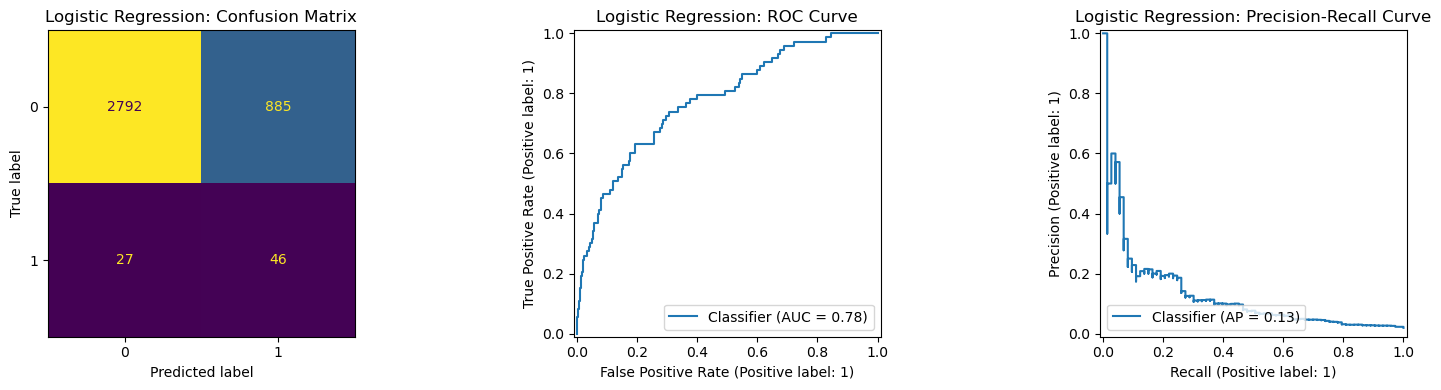

In [18]:
logistic = make_pipeline(
    LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    X_train,
    scale_numeric=True
)

logistic.fit(X_train, y_train)
metrics, scores = evaluate_classifier(
    logistic, X_test, y_test, "Logistic Regression"
)

model_results.append(metrics)
trained_models["Logistic Regression"] = logistic
test_scores_by_model["Logistic Regression"] = scores

# 13. Model 2 — K-Nearest Neighbors

KNN demonstrates similarity-based classification and the importance of scaling. A compact numeric feature set keeps the distance calculation interpretable and efficient.

K-Nearest Neighbors
              precision    recall  f1-score   support

           0      0.981     1.000     0.990      3677
           1      0.000     0.000     0.000        73

    accuracy                          0.981      3750
   macro avg      0.490     0.500     0.495      3750
weighted avg      0.961     0.981     0.971      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,K-Nearest Neighbors,0.5000,0.0000,0.0000,0.0000,0.5449,0.0311


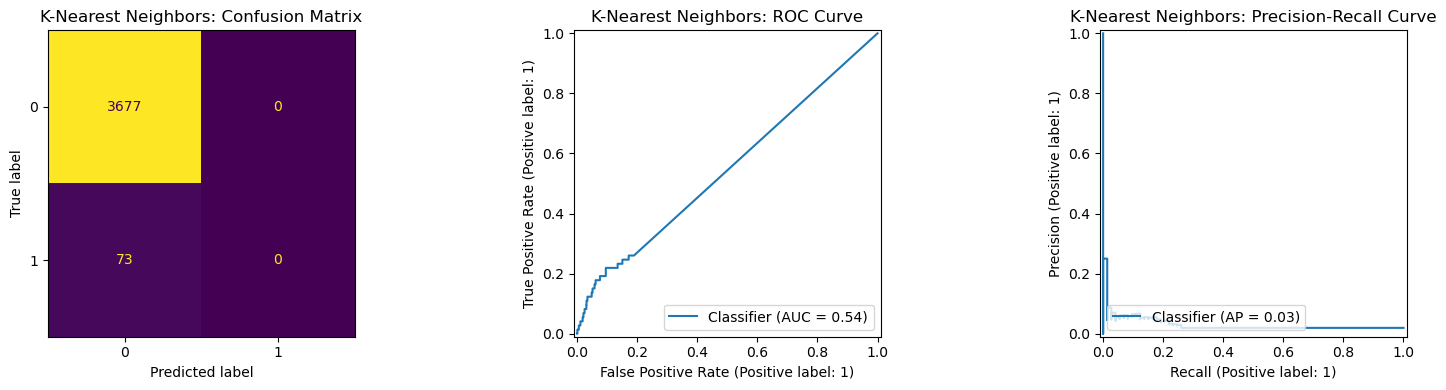

In [19]:
KNN_FEATURES = [
    "trade_amount", "quantity", "settlement_days",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts",
    "trade_amendments", "hours_until_cutoff",
    "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "trade_size_ratio", "processing_delay_total",
    "operational_touch_count", "cutoff_pressure"
]

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=15, weights="distance"))
])

knn.fit(train_df[KNN_FEATURES], y_train)
metrics, scores = evaluate_classifier(
    knn, test_df[KNN_FEATURES], y_test, "K-Nearest Neighbors"
)

model_results.append(metrics)
trained_models["K-Nearest Neighbors"] = knn
test_scores_by_model["K-Nearest Neighbors"] = scores

# 14. Model 3 — Decision Tree

Decision Trees learn nonlinear business-like rules but can overfit. Depth and leaf size are constrained.

Decision Tree
              precision    recall  f1-score   support

           0      0.988     0.652     0.786      3677
           1      0.033     0.603     0.063        73

    accuracy                          0.651      3750
   macro avg      0.511     0.628     0.424      3750
weighted avg      0.969     0.651     0.772      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,Decision Tree,0.5000,0.0333,0.6027,0.0631,0.6389,0.0648


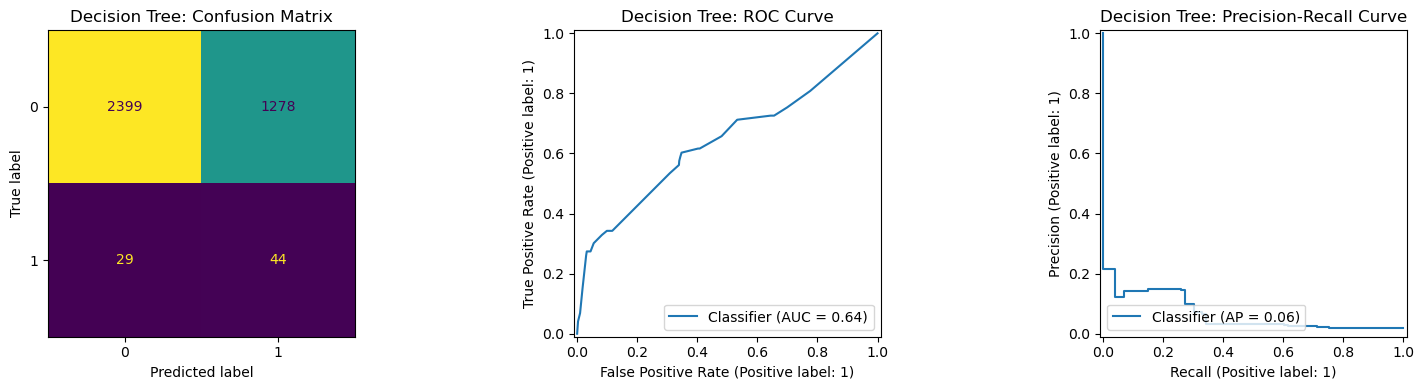

In [20]:
decision_tree = make_pipeline(
    DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=30,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    X_train,
    scale_numeric=False
)

decision_tree.fit(X_train, y_train)
metrics, scores = evaluate_classifier(
    decision_tree, X_test, y_test, "Decision Tree"
)

model_results.append(metrics)
trained_models["Decision Tree"] = decision_tree
test_scores_by_model["Decision Tree"] = scores

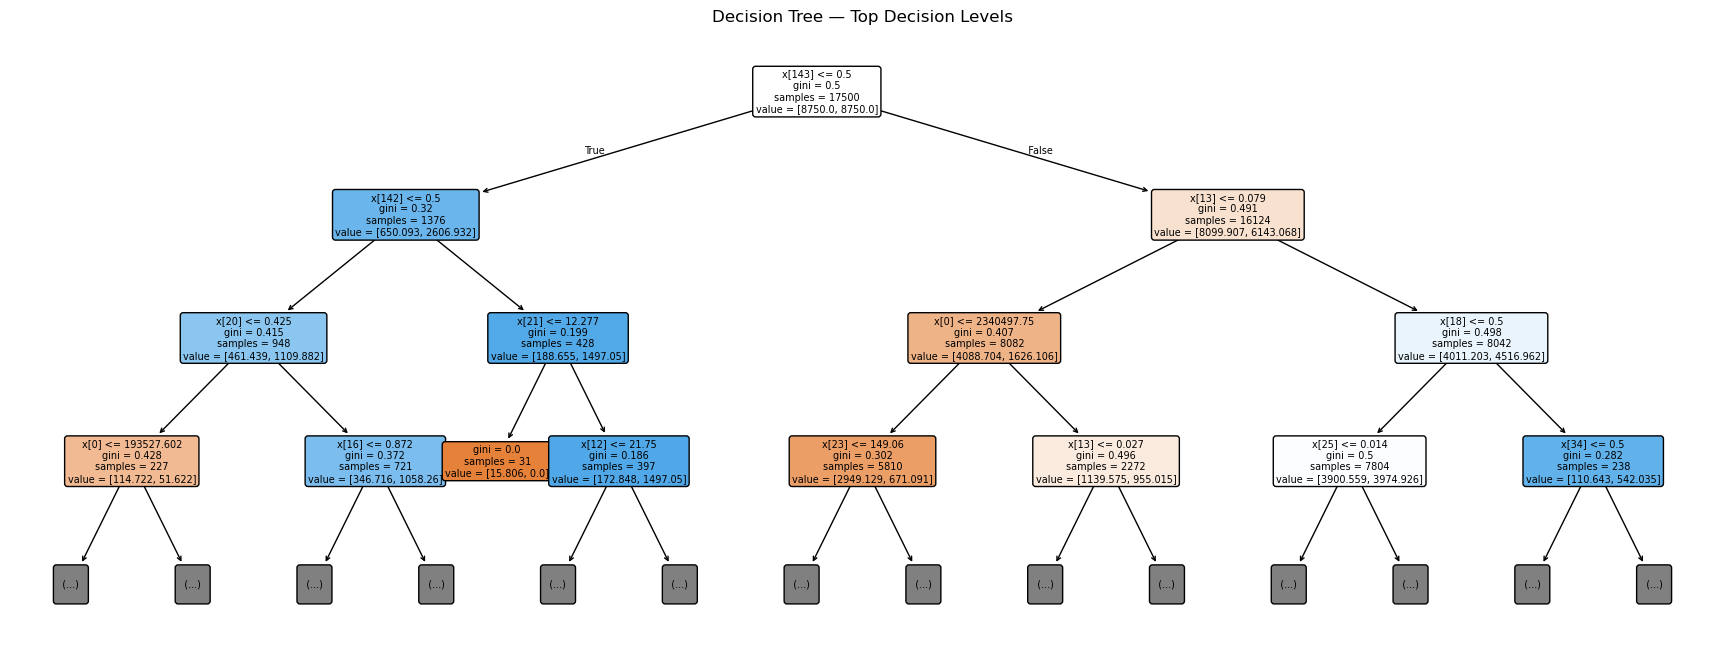

In [21]:
tree_estimator = decision_tree.named_steps["model"]
plt.figure(figsize=(22, 8))
plot_tree(
    tree_estimator,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Decision Tree — Top Decision Levels")
plt.show()

# 15. Model 4 — Random Forest

Random Forest reduces the variance of a single tree by aggregating many decorrelated trees.

Random Forest
              precision    recall  f1-score   support

           0      0.981     0.999     0.990      3677
           1      0.167     0.014     0.025        73

    accuracy                          0.979      3750
   macro avg      0.574     0.506     0.507      3750
weighted avg      0.965     0.979     0.971      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.5000,0.1667,0.0137,0.0253,0.7204,0.0800


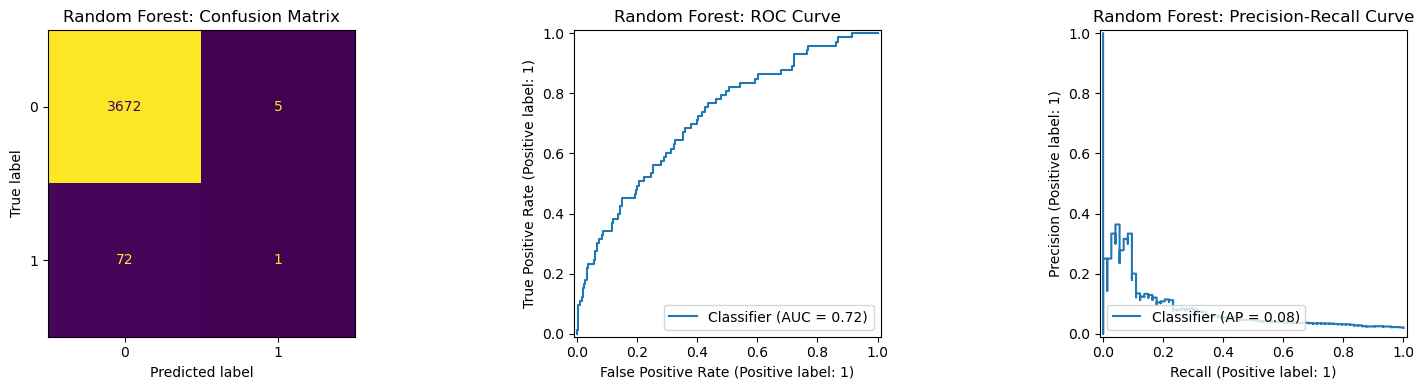

In [22]:
random_forest = make_pipeline(
    RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    X_train,
    scale_numeric=False
)

random_forest.fit(X_train, y_train)
metrics, scores = evaluate_classifier(
    random_forest, X_test, y_test, "Random Forest"
)

model_results.append(metrics)
trained_models["Random Forest"] = random_forest
test_scores_by_model["Random Forest"] = scores

# 16. Model 5 — Support Vector Machine

SVM can model nonlinear decision boundaries but may be less operationally attractive for very large datasets. A training sample and compact numeric feature set are used to keep runtime reasonable.

Support Vector Machine
              precision    recall  f1-score   support

           0      0.981     1.000     0.990      3677
           1      0.000     0.000     0.000        73

    accuracy                          0.981      3750
   macro avg      0.490     0.500     0.495      3750
weighted avg      0.961     0.981     0.971      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,Support Vector Machine,0.5000,0.0000,0.0000,0.0000,0.5265,0.0256


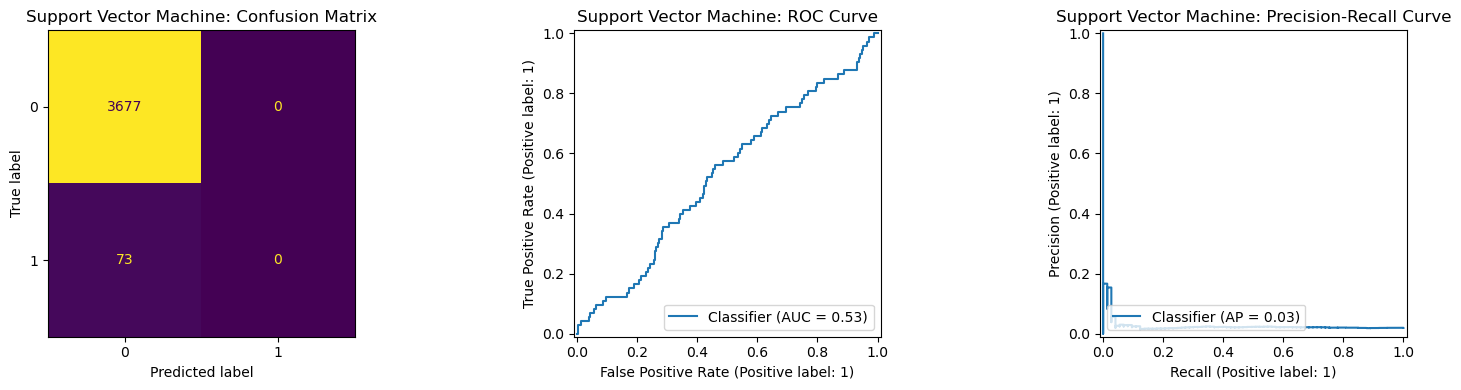

In [23]:
svm_train = train_df.sample(min(12000, len(train_df)), random_state=RANDOM_STATE)

svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=2.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

svm.fit(svm_train[KNN_FEATURES], svm_train[TARGET])
metrics, scores = evaluate_classifier(
    svm, test_df[KNN_FEATURES], y_test, "Support Vector Machine"
)

model_results.append(metrics)
trained_models["Support Vector Machine"] = svm
test_scores_by_model["Support Vector Machine"] = scores

# 17. Dimensionality Reduction — PCA and SVD

Question:

> **Can the numeric feature space be compressed while retaining most of its variance?**

PCA and SVD are demonstrated on standardized numeric features.

,component,explained_variance_ratio,cumulative_variance
0,1,0.1084,0.1084
1,2,0.0953,0.2037
2,3,0.0839,0.2876
3,4,0.0738,0.3614
4,5,0.0589,0.4203
5,6,0.0550,0.4754
6,7,0.0486,0.5240
7,8,0.0416,0.5655
8,9,0.0402,0.6058
9,10,0.0377,0.6435


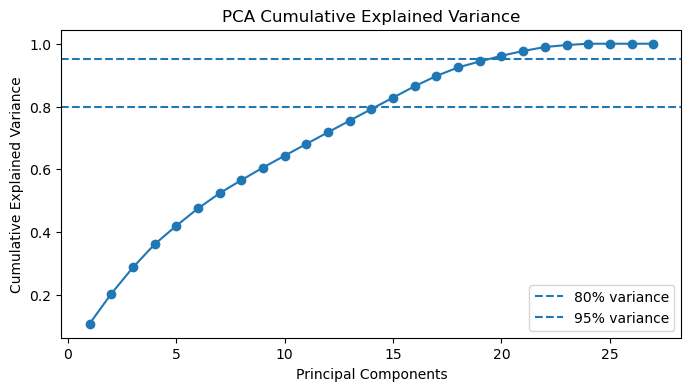

Components for >=80% variance: 15
Components for >=95% variance: 20


In [24]:
PCA_FEATURES = X_train.select_dtypes(include=np.number).columns.tolist()

scaler_pca = StandardScaler()
X_pca_train = scaler_pca.fit_transform(X_train[PCA_FEATURES])
X_pca_test = scaler_pca.transform(X_test[PCA_FEATURES])

pca = PCA(random_state=RANDOM_STATE)
pca.fit(X_pca_train)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

variance_table = pd.DataFrame({
    "component": np.arange(1, len(cumulative_variance) + 1),
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance": cumulative_variance
})
display(variance_table.head(15))

plt.figure(figsize=(8, 4))
plt.plot(variance_table["component"], variance_table["cumulative_variance"], marker="o")
plt.axhline(0.80, linestyle="--", label="80% variance")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.show()

n80 = int(np.argmax(cumulative_variance >= 0.80) + 1)
n95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print("Components for >=80% variance:", n80)
print("Components for >=95% variance:", n95)

In [25]:
U, sigma, VT = np.linalg.svd(X_pca_train, full_matrices=False)

svd_variance = (sigma ** 2) / np.sum(sigma ** 2)
svd_cumulative = np.cumsum(svd_variance)

svd_table = pd.DataFrame({
    "component": np.arange(1, len(sigma) + 1),
    "singular_value": sigma,
    "variance_share": svd_variance,
    "cumulative_variance": svd_cumulative,
})

display(svd_table.head(15))

,component,singular_value,variance_share,cumulative_variance
0,1,226.3015,0.1084,0.1084
1,2,212.2405,0.0953,0.2037
2,3,199.1285,0.0839,0.2876
3,4,186.7347,0.0738,0.3614
4,5,166.8153,0.0589,0.4203
5,6,161.2744,0.0550,0.4754
6,7,151.5160,0.0486,0.5240
7,8,140.1528,0.0416,0.5655
8,9,137.8606,0.0402,0.6058
9,10,133.4578,0.0377,0.6435


# 18. Unsupervised Learning — K-Means Trade-Risk Segmentation

Classification asks **“Will this trade fail?”** Clustering asks:

> **“What naturally occurring types of trades exist in operational-risk feature space?”**

,k,inertia,silhouette
0,2,"224,549.0162",0.1084
1,3,"200,322.7389",0.1229
2,4,"181,289.6925",0.1306
3,5,"169,968.8348",0.1202
4,6,"159,771.0251",0.1252
5,7,"151,825.3145",0.1153
6,8,"145,679.7993",0.1085


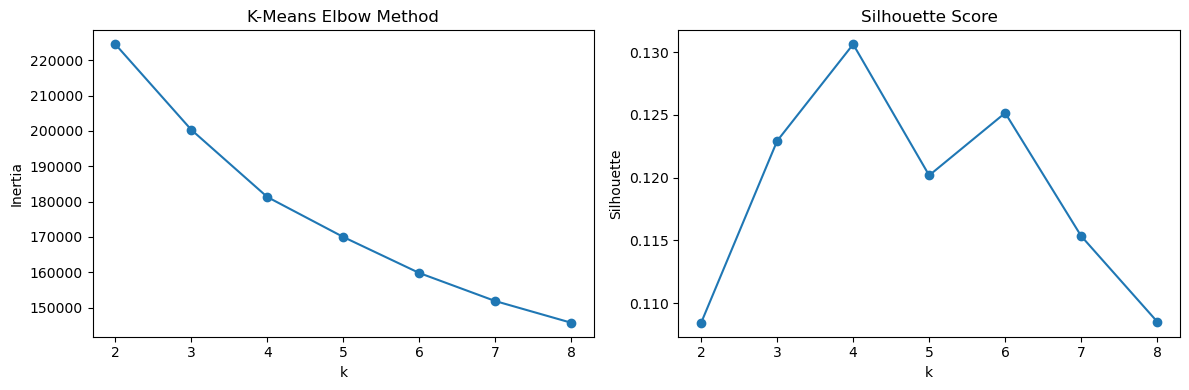

In [26]:
CLUSTER_FEATURES = [
    "log_trade_amount",
    "confirmation_delay_log",
    "processing_delay_total",
    "operational_touch_count",
    "hours_until_cutoff",
    "prior_fail_rate_30d",
    "security_liquidity_score",
    "market_volatility_index",
    "inventory_shortfall_indicator",
    "trade_size_ratio",
]

cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(df_model[CLUSTER_FEATURES])

k_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    sample_idx = np.random.default_rng(RANDOM_STATE).choice(
        len(X_cluster), size=min(4000, len(X_cluster)), replace=False
    )
    sil = silhouette_score(X_cluster[sample_idx], labels[sample_idx])
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})

k_selection = pd.DataFrame(k_rows)
display(k_selection)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_selection["k"], k_selection["inertia"], marker="o")
axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_selection["k"], k_selection["silhouette"], marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

In [27]:
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=20)
df_model["cluster"] = kmeans.fit_predict(X_cluster)

cluster_profile = (
    df_model.groupby("cluster")[CLUSTER_FEATURES + [TARGET]]
    .mean()
    .round(4)
)

cluster_counts = df_model["cluster"].value_counts().sort_index().rename("trade_count")
cluster_profile = cluster_profile.join(cluster_counts)

display(cluster_profile)

,log_trade_amount,confirmation_delay_log,processing_delay_total,operational_touch_count,hours_until_cutoff,prior_fail_rate_30d,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,trade_size_ratio,settlement_failed,trade_count
cluster,,,,,,,,,,,,
0,14.0341,3.2125,76.8333,1.7003,16.9884,0.0913,0.6628,20.1748,1.0000,2.8698,0.0633,774
1,13.8581,3.8286,103.3477,1.7471,16.9391,0.0916,0.6590,20.0983,0.0000,1.8248,0.0175,10509
2,13.8208,2.7449,55.4519,1.7286,16.9667,0.0936,0.6570,20.1893,0.0000,1.7445,0.0160,11947
3,15.9576,3.2211,76.0520,1.6921,16.7440,0.0936,0.6657,20.2134,0.0034,17.4532,0.0367,1770


**Interpretation rule:** Assign descriptive labels only after examining the cluster profile. Do not force labels that the actual centroid patterns do not support.

# 19. Anomaly Detection — Isolation Forest

Isolation Forest identifies transactions that look unusual compared with the broader population, even if they do not match a previously labeled failure pattern.

In [28]:
iso = IsolationForest(
    n_estimators=250,
    contamination=0.02,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

iso_labels = iso.fit_predict(X_cluster)
df_model["is_anomaly"] = (iso_labels == -1).astype(int)
df_model["anomaly_score"] = -iso.score_samples(X_cluster)

anomaly_summary = pd.DataFrame({
    "group": ["Normal", "Anomaly"],
    "count": [
        (df_model["is_anomaly"] == 0).sum(),
        (df_model["is_anomaly"] == 1).sum()
    ],
    "failure_rate": [
        df_model.loc[df_model["is_anomaly"] == 0, TARGET].mean(),
        df_model.loc[df_model["is_anomaly"] == 1, TARGET].mean()
    ]
})
display(anomaly_summary)

display(
    df_model.nlargest(15, "anomaly_score")[
        ["trade_id", "trade_date", TARGET, "anomaly_score"] + CLUSTER_FEATURES
    ]
)

,group,count,failure_rate
0,Normal,24500,0.0182
1,Anomaly,500,0.0840


,trade_id,trade_date,settlement_failed,anomaly_score,log_trade_amount,confirmation_delay_log,processing_delay_total,operational_touch_count,hours_until_cutoff,prior_fail_rate_30d,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,trade_size_ratio
21027,TRD0005935,2025-06-10,1,0.6871,15.9399,4.7111,158.2400,4,16.3600,0.1229,0.6615,9.4200,1,34.0663
14940,TRD0005862,2024-09-24,1,0.6870,16.9581,3.7565,82.8200,4,12.6100,0.1892,0.7101,28.2900,1,40.0000
5501,TRD0023156,2023-08-22,0,0.6738,15.7882,4.2354,194.7500,3,18.6200,0.1649,0.3715,21.4400,1,30.1996
24530,TRD0016798,2025-11-11,0,0.6634,16.8074,1.7475,53.3200,4,26.3700,0.2135,0.7076,28.0600,0,40.0000
15039,TRD0006304,2024-09-27,1,0.6631,16.9344,2.7695,88.0900,1,11.3400,0.0110,0.4502,10.3500,1,34.7152
253,TRD0013220,2023-01-11,1,0.6620,15.4978,2.5885,98.6000,3,12.2200,0.0479,0.2180,23.0300,1,40.0000
21847,TRD0012764,2025-07-16,0,0.6574,16.9592,2.1552,29.4400,2,19.2800,0.1139,0.6042,15.2600,1,37.0879
18252,TRD0014825,2025-02-12,0,0.6504,16.5785,3.2802,87.9100,2,20.5700,0.0746,0.1336,18.6300,1,40.0000
13869,TRD0011424,2024-08-08,0,0.6478,16.2938,3.6246,62.4900,2,31.6100,0.1514,0.2631,14.5200,1,18.2418
4421,TRD0003052,2023-07-06,0,0.6471,16.3745,4.2600,114.5900,4,16.9300,0.2413,0.2127,27.0200,0,26.8588


# 20. Advanced Boosting — XGBoost

XGBoost is a strong candidate for structured/tabular financial data. `scale_pos_weight` helps address the rare positive class.

XGBoost
              precision    recall  f1-score   support

           0      0.985     0.963     0.974      3677
           1      0.122     0.260     0.166        73

    accuracy                          0.949      3750
   macro avg      0.553     0.612     0.570      3750
weighted avg      0.968     0.949     0.958      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,XGBoost,0.5000,0.1218,0.2603,0.1659,0.6975,0.0860


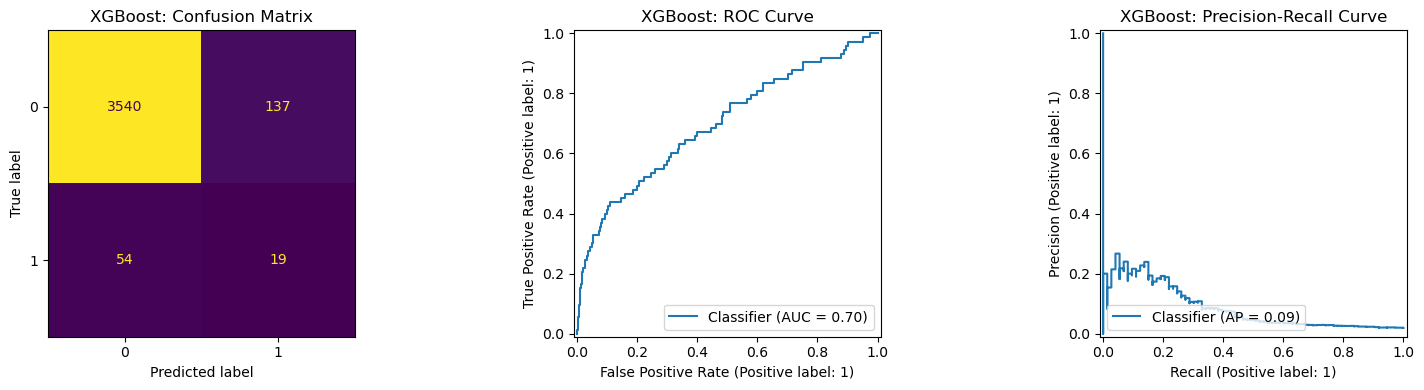

In [29]:
try:
    from xgboost import XGBClassifier

    negative = int((y_train == 0).sum())
    positive = int((y_train == 1).sum())
    scale_pos_weight = negative / max(positive, 1)

    xgboost_model = make_pipeline(
        XGBClassifier(
            n_estimators=350,
            max_depth=5,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_weight=4,
            reg_lambda=2.0,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        X_train,
        scale_numeric=False
    )

    xgboost_model.fit(X_train, y_train)
    metrics, scores = evaluate_classifier(
        xgboost_model, X_test, y_test, "XGBoost"
    )

    model_results.append(metrics)
    trained_models["XGBoost"] = xgboost_model
    test_scores_by_model["XGBoost"] = scores

except ImportError:
    print("XGBoost is not installed. Install with: pip install xgboost")

# 21. Categorical Boosting — CatBoost

CatBoost is well suited to high-cardinality categorical variables such as counterparties, custodians, markets, and settlement locations.

In [30]:
try:
    from catboost import CatBoostClassifier

    CATBOOST_FEATURES = MODEL_FEATURES.copy()
    cat_train = train_df[CATBOOST_FEATURES].copy()
    cat_test = test_df[CATBOOST_FEATURES].copy()

    categorical_cols = cat_train.select_dtypes(exclude=np.number).columns.tolist()
    cat_indices = [cat_train.columns.get_loc(c) for c in categorical_cols]

    for c in categorical_cols:
        cat_train[c] = cat_train[c].fillna("UNKNOWN").astype(str)
        cat_test[c] = cat_test[c].fillna("UNKNOWN").astype(str)

    catboost_model = CatBoostClassifier(
        iterations=450,
        depth=6,
        learning_rate=0.04,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=RANDOM_STATE,
        verbose=False
    )

    catboost_model.fit(cat_train, y_train, cat_features=cat_indices)

    cat_scores = catboost_model.predict_proba(cat_test)[:, 1]
    cat_pred = (cat_scores >= 0.50).astype(int)

    cat_metrics = {
        "model": "CatBoost",
        "threshold": 0.50,
        "precision": precision_score(y_test, cat_pred, zero_division=0),
        "recall": recall_score(y_test, cat_pred, zero_division=0),
        "f1": f1_score(y_test, cat_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, cat_scores),
        "pr_auc": average_precision_score(y_test, cat_scores)
    }

    print(classification_report(y_test, cat_pred, digits=3, zero_division=0))
    display(pd.DataFrame([cat_metrics]))

    model_results.append(cat_metrics)
    trained_models["CatBoost"] = catboost_model
    test_scores_by_model["CatBoost"] = cat_scores

except ImportError:
    print("CatBoost is not installed. Install with: pip install catboost")

              precision    recall  f1-score   support

           0      0.985     0.965     0.975      3677
           1      0.122     0.247     0.164        73

    accuracy                          0.951      3750
   macro avg      0.554     0.606     0.569      3750
weighted avg      0.968     0.951     0.959      3750



,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,CatBoost,0.5000,0.1224,0.2466,0.1636,0.7015,0.1206


# 22. Consolidated Supervised Model Comparison

Final model selection should emphasize rare-event performance and operational practicality—not accuracy alone.

,model,threshold,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.5000,0.0494,0.6301,0.0916,0.7781,0.1308
6,CatBoost,0.5000,0.1224,0.2466,0.1636,0.7015,0.1206
5,XGBoost,0.5000,0.1218,0.2603,0.1659,0.6975,0.0860
3,Random Forest,0.5000,0.1667,0.0137,0.0253,0.7204,0.0800
2,Decision Tree,0.5000,0.0333,0.6027,0.0631,0.6389,0.0648
1,K-Nearest Neighbors,0.5000,0.0000,0.0000,0.0000,0.5449,0.0311
4,Support Vector Machine,0.5000,0.0000,0.0000,0.0000,0.5265,0.0256


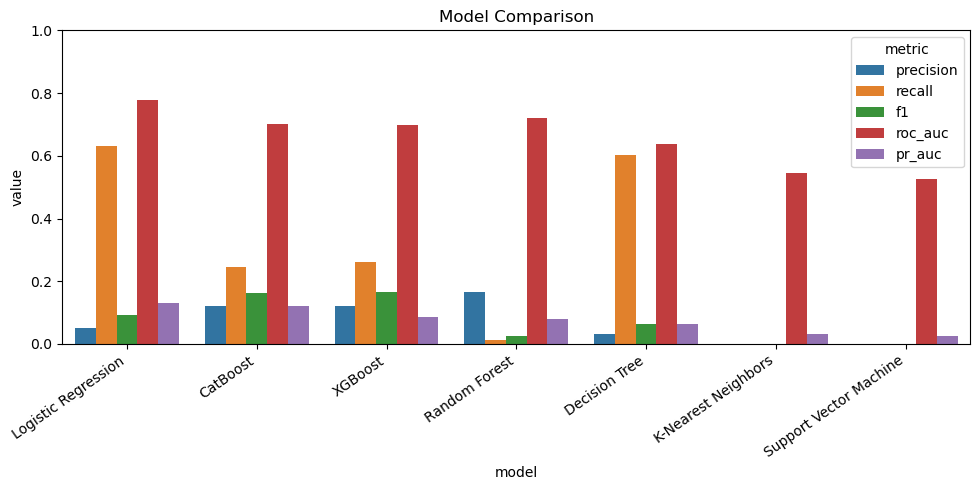

In [31]:
scorecard = pd.DataFrame(model_results).drop_duplicates(subset=["model"], keep="last")

if not scorecard.empty:
    scorecard = scorecard.sort_values(["pr_auc", "recall"], ascending=False)
    display(scorecard)

    plt.figure(figsize=(10, 5))
    plot_df = scorecard.melt(
        id_vars="model",
        value_vars=["precision", "recall", "f1", "roc_auc", "pr_auc"],
        var_name="metric",
        value_name="value"
    )
    sns.barplot(data=plot_df, x="model", y="value", hue="metric")
    plt.title("Model Comparison")
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

### Model-selection discussion

Choose the preferred model only after reviewing the actual results. Justify the choice using a combination of PR-AUC, recall, precision, interpretability, computational cost, and operational scalability.

# 23. Classification Threshold Optimization

The default threshold of `0.50` is not necessarily appropriate for a rare but costly failure event.

Selected candidate: Logistic Regression


,threshold,precision,recall,f1,alerts,false_negatives,false_positives
0,0.0500,0.0207,1.0000,0.0406,3525,0,3452
1,0.1000,0.0229,0.9863,0.0447,3147,1,3075
2,0.1500,0.0254,0.9726,0.0495,2794,2,2723
3,0.2000,0.0270,0.9041,0.0524,2445,7,2379
4,0.2500,0.0294,0.8630,0.0568,2146,10,2083
5,0.3000,0.0316,0.8082,0.0607,1870,14,1811
6,0.3500,0.0366,0.7945,0.0699,1586,15,1528
7,0.4000,0.0415,0.7534,0.0786,1326,18,1271
8,0.4500,0.0460,0.7123,0.0865,1130,21,1078
9,0.5000,0.0494,0.6301,0.0916,931,27,885


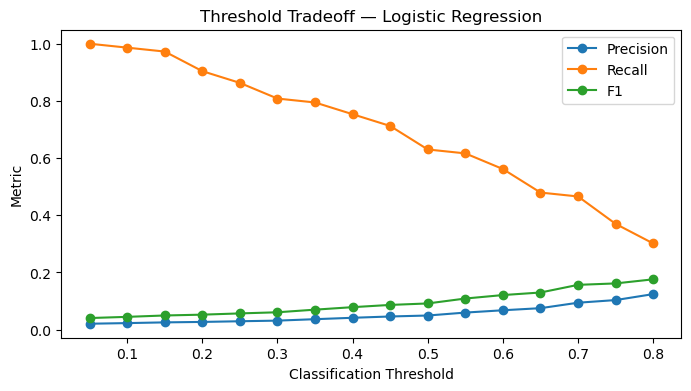

In [32]:
candidate_names = [
    m for m in ["CatBoost", "XGBoost", "Random Forest", "Logistic Regression"]
    if m in test_scores_by_model
]

eligible = scorecard.loc[scorecard["model"].isin(candidate_names)].copy()
selected_model_name = (
    eligible.sort_values("pr_auc", ascending=False).iloc[0]["model"]
    if not eligible.empty else scorecard.iloc[0]["model"]
)

selected_test_scores = test_scores_by_model[selected_model_name]

threshold_rows = []
for threshold in np.arange(0.05, 0.81, 0.05):
    pred = (selected_test_scores >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "alerts": int(pred.sum()),
        "false_negatives": int(((y_test == 1) & (pred == 0)).sum()),
        "false_positives": int(((y_test == 0) & (pred == 1)).sum())
    })

threshold_table = pd.DataFrame(threshold_rows)
print("Selected candidate:", selected_model_name)
display(threshold_table)

plt.figure(figsize=(8, 4))
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], marker="o", label="F1")
plt.xlabel("Classification Threshold")
plt.ylabel("Metric")
plt.title(f"Threshold Tradeoff — {selected_model_name}")
plt.legend()
plt.show()

# 24. Business-Cost Optimization

Illustrative academic assumptions:

- False Negative cost = `$5,000`
- False Positive investigation cost = `$50`

These values are hypothetical and must not be represented as actual institutional costs.

,threshold,precision,recall,f1,alerts,false_negatives,false_positives,expected_cost
0,0.0500,0.0207,1.0000,0.0406,3525,0,3452,172600
1,0.1000,0.0229,0.9863,0.0447,3147,1,3075,158750
2,0.1500,0.0254,0.9726,0.0495,2794,2,2723,146150
3,0.2000,0.0270,0.9041,0.0524,2445,7,2379,153950
4,0.2500,0.0294,0.8630,0.0568,2146,10,2083,154150
5,0.3000,0.0316,0.8082,0.0607,1870,14,1811,160550
6,0.3500,0.0366,0.7945,0.0699,1586,15,1528,151400
7,0.4000,0.0415,0.7534,0.0786,1326,18,1271,153550
8,0.4500,0.0460,0.7123,0.0865,1130,21,1078,158900
9,0.5000,0.0494,0.6301,0.0916,931,27,885,179250


Illustrative cost-optimal threshold: 0.15
Expected cost: $146,150
Recall: 97.26%
Precision: 2.54%
Alerts: 2794


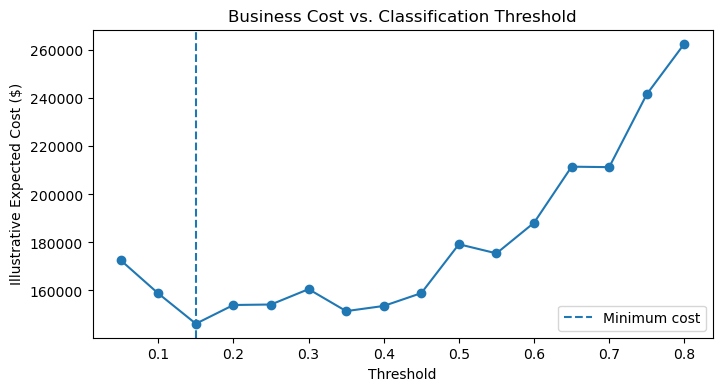

In [33]:
FALSE_NEGATIVE_COST = 5000
FALSE_POSITIVE_COST = 50

cost_table = threshold_table.copy()
cost_table["expected_cost"] = (
    cost_table["false_negatives"] * FALSE_NEGATIVE_COST +
    cost_table["false_positives"] * FALSE_POSITIVE_COST
)

best_cost_row = cost_table.loc[cost_table["expected_cost"].idxmin()]
display(cost_table)

print("Illustrative cost-optimal threshold:", round(best_cost_row["threshold"], 2))
print("Expected cost:", f"${best_cost_row['expected_cost']:,.0f}")
print("Recall:", f"{best_cost_row['recall']:.2%}")
print("Precision:", f"{best_cost_row['precision']:.2%}")
print("Alerts:", int(best_cost_row["alerts"]))

plt.figure(figsize=(8, 4))
plt.plot(cost_table["threshold"], cost_table["expected_cost"], marker="o")
plt.axvline(best_cost_row["threshold"], linestyle="--", label="Minimum cost")
plt.xlabel("Threshold")
plt.ylabel("Illustrative Expected Cost ($)")
plt.title("Business Cost vs. Classification Threshold")
plt.legend()
plt.show()

# 25. Explainable AI — SHAP

SHAP can provide:

1. **Global explanation** — which features generally drive predictions?
2. **Local explanation** — why was one specific trade scored as high risk?

,feature,mean_abs_shap
25,num__counterparty_risk_gap,0.3835
14,num__prior_fail_rate_90d,0.3412
143,cat__ssi_status_VALID,0.2611
20,num__trade_size_ratio,0.2553
0,num__trade_amount,0.2480
12,num__hours_until_cutoff,0.2246
16,num__security_liquidity_score,0.2181
13,num__prior_fail_rate_30d,0.2146
23,num__processing_delay_total,0.1627
8,num__allocation_delay_minutes,0.1617


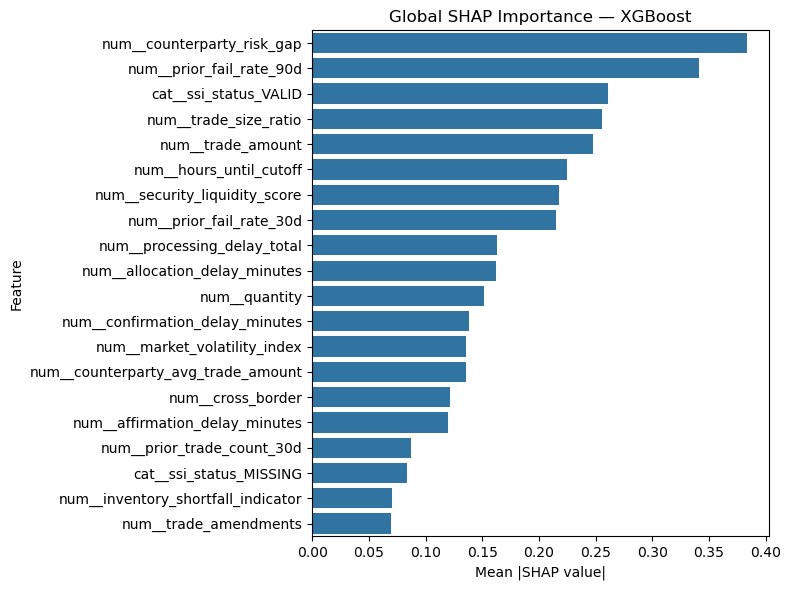

In [34]:
try:
    import shap

    shap_source_name = "XGBoost" if "XGBoost" in trained_models else "Random Forest"
    shap_pipeline = trained_models.get(shap_source_name)

    if shap_pipeline is None:
        print("No compatible tree pipeline available for SHAP.")
    else:
        preprocessor = shap_pipeline.named_steps["preprocessor"]
        estimator = shap_pipeline.named_steps["model"]

        X_test_transformed = preprocessor.transform(X_test)
        sample_size = min(500, X_test_transformed.shape[0])
        X_shap = X_test_transformed[:sample_size]
        feature_names = preprocessor.get_feature_names_out()

        explainer = shap.TreeExplainer(estimator)
        shap_values = explainer.shap_values(X_shap)

        if isinstance(shap_values, list):
            shap_array = shap_values[-1]
        else:
            shap_array = np.asarray(shap_values)
            if shap_array.ndim == 3:
                shap_array = shap_array[:, :, -1]

        mean_abs_shap = np.abs(shap_array).mean(axis=0)
        shap_importance = (
            pd.DataFrame({
                "feature": feature_names,
                "mean_abs_shap": mean_abs_shap
            })
            .sort_values("mean_abs_shap", ascending=False)
            .head(20)
        )

        display(shap_importance)

        plt.figure(figsize=(8, 6))
        sns.barplot(data=shap_importance, x="mean_abs_shap", y="feature")
        plt.title(f"Global SHAP Importance — {shap_source_name}")
        plt.xlabel("Mean |SHAP value|")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

except ImportError:
    print("SHAP is not installed. Install with: pip install shap")
except Exception as exc:
    print("SHAP section could not run in this environment:", exc)

### Local explainability discussion

For the final submitted notebook, select several high-risk trades and document:

- Predicted probability
- Primary positive risk drivers
- Factors reducing risk
- Operational follow-up suggested by those drivers

Explanations should remain grounded in the model output.

# 26. NLP Use Case — Classifying Final Failure Reasons

This is a **separate post-event analytics problem**. Final failure descriptions are not allowed in the pre-settlement classifier.

The NLP task demonstrates TF-IDF and text classification.

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

nlp_df = df.loc[
    df[TARGET] == 1,
    ["failure_reason_description", "failure_reason", "trade_date"]
].dropna().copy()

nlp_cut = int(len(nlp_df) * 0.80)
nlp_train = nlp_df.iloc[:nlp_cut]
nlp_test = nlp_df.iloc[nlp_cut:]

nlp_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=5000
    )),
    ("model", LogisticRegression(
        max_iter=1200,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

nlp_pipeline.fit(
    nlp_train["failure_reason_description"],
    nlp_train["failure_reason"]
)

nlp_pred = nlp_pipeline.predict(nlp_test["failure_reason_description"])

print(classification_report(
    nlp_test["failure_reason"],
    nlp_pred,
    digits=3,
    zero_division=0
))

display(pd.DataFrame({
    "description": nlp_test["failure_reason_description"].head(10),
    "actual": nlp_test["failure_reason"].head(10),
    "predicted": nlp_pred[:10]
}))

                                     precision    recall  f1-score   support

     Counterparty Operational Issue      1.000     1.000     1.000        39
               Funding / Cash Issue      1.000     1.000     1.000         5
Insufficient Securities / Inventory      1.000     1.000     1.000         6
    Late Confirmation / Affirmation      1.000     1.000     1.000         8
 Market Holiday / Calendar Mismatch      1.000     1.000     1.000         4
        Other Operational Exception      1.000     1.000     1.000         5
       SSI / Settlement Instruction      1.000     1.000     1.000        21
               Trade Matching Break      1.000     1.000     1.000        10

                           accuracy                          1.000        98
                          macro avg      1.000     1.000     1.000        98
                       weighted avg      1.000     1.000     1.000        98



,description,actual,predicted
20088,Settlement failed after delayed confirmation o...,Late Confirmation / Affirmation,Late Confirmation / Affirmation
20095,Settlement failed due to insufficient securiti...,Insufficient Securities / Inventory,Insufficient Securities / Inventory
20140,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
20217,Settlement failed because required funding or ...,Funding / Cash Issue,Funding / Cash Issue
20225,Settlement failed because settlement instructi...,SSI / Settlement Instruction,SSI / Settlement Instruction
20299,Settlement failed because settlement instructi...,SSI / Settlement Instruction,SSI / Settlement Instruction
20303,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
20355,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
20366,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
20386,Settlement failed after delayed confirmation o...,Late Confirmation / Affirmation,Late Confirmation / Affirmation


# 27. Grounded Generative-AI Explanation Layer

Safe architecture:

**ML model → probability → SHAP/risk drivers → controlled prompt → human-readable summary**

The LLM should not calculate the risk independently, change the score, invent failure reasons, or make autonomous settlement decisions.

In [36]:
def grounded_risk_narrative(
    trade_id,
    probability,
    top_drivers,
    recommended_actions=None
):
    risk_band = (
        "CRITICAL" if probability >= 0.80 else
        "HIGH" if probability >= 0.60 else
        "MEDIUM" if probability >= 0.30 else
        "LOW"
    )

    driver_text = "; ".join(top_drivers[:4]) if top_drivers else "No dominant driver identified"
    action_text = (
        "; ".join(recommended_actions)
        if recommended_actions
        else "Review according to standard operations risk procedures"
    )

    return (
        f"Trade {trade_id} has a modeled settlement-failure probability of "
        f"{probability:.1%} ({risk_band} risk). "
        f"Primary modeled risk drivers: {driver_text}. "
        f"Suggested operational follow-up: {action_text}. "
        "This is a decision-support prediction, not a guaranteed outcome."
    )

print(
    grounded_risk_narrative(
        trade_id="TRD-EXAMPLE",
        probability=0.87,
        top_drivers=[
            "missing/changed settlement instruction",
            "elevated recent counterparty failure rate",
            "late confirmation",
            "high trade-size ratio"
        ],
        recommended_actions=[
            "validate settlement instructions",
            "contact the counterparty before cutoff"
        ]
    )
)

Trade TRD-EXAMPLE has a modeled settlement-failure probability of 87.0% (CRITICAL risk). Primary modeled risk drivers: missing/changed settlement instruction; elevated recent counterparty failure rate; late confirmation; high trade-size ratio. Suggested operational follow-up: validate settlement instructions; contact the counterparty before cutoff. This is a decision-support prediction, not a guaranteed outcome.


# 28. Operationalization — High-Risk Trade Queue

The final output should be actionable. Test-set trades are ranked by modeled failure probability and routed according to the illustrative cost-optimal threshold.

In [37]:
optimal_threshold = float(best_cost_row["threshold"])

ops_queue = test_df[
    ["trade_id", "trade_date", "settlement_date", "asset_class",
     "counterparty_id", "trade_amount", "ssi_status",
     "confirmation_delay_minutes", "prior_fail_rate_30d",
     "inventory_shortfall_indicator", TARGET]
].copy()

ops_queue["predicted_failure_probability"] = selected_test_scores
ops_queue["risk_flag"] = (
    ops_queue["predicted_failure_probability"] >= optimal_threshold
).astype(int)

def risk_band(p):
    if p >= 0.80:
        return "CRITICAL"
    if p >= 0.60:
        return "HIGH"
    if p >= 0.30:
        return "MEDIUM"
    return "LOW"

ops_queue["risk_band"] = ops_queue["predicted_failure_probability"].apply(risk_band)

high_risk_queue = (
    ops_queue.loc[ops_queue["risk_flag"] == 1]
             .sort_values("predicted_failure_probability", ascending=False)
)

print("Model used:", selected_model_name)
print("Threshold:", optimal_threshold)
print("Trades routed for review:", len(high_risk_queue))
display(high_risk_queue.head(25))

Model used: Logistic Regression
Threshold: 0.15000000000000002
Trades routed for review: 2794


,trade_id,trade_date,settlement_date,asset_class,counterparty_id,trade_amount,ssi_status,confirmation_delay_minutes,prior_fail_rate_30d,inventory_shortfall_indicator,settlement_failed,predicted_failure_probability,risk_flag,risk_band
21469,TRD0014790,2025-06-30,2025-07-01,Equity,CP079,"6,071,119.2900",MISSING,35.3600,0.2127,0,1,0.9958,1,CRITICAL
22820,TRD0015122,2025-08-29,2025-08-30,Corporate Bond,CP063,"3,764,069.5700",CHANGED,7.7400,0.2942,0,0,0.9882,1,CRITICAL
21515,TRD0000232,2025-07-01,2025-07-03,Equity,CP059,"1,703,158.8100",MISSING,40.5700,0.0833,1,0,0.9802,1,CRITICAL
23955,TRD0015401,2025-10-17,2025-10-19,Government Bond,CP060,"448,870.0100",MISSING,45.4800,0.1655,1,1,0.9801,1,CRITICAL
23106,TRD0000452,2025-09-10,2025-09-13,Equity,CP039,"1,575,371.6400",MISSING,43.9700,0.2080,0,1,0.9786,1,CRITICAL
24000,TRD0015072,2025-10-20,2025-10-22,Equity,CP014,"4,202,146.2400",VALID,5.0300,0.0909,1,0,0.9783,1,CRITICAL
21387,TRD0001856,2025-06-25,2025-06-26,Government Bond,CP028,"8,257,775.3500",MISSING,18.7100,0.1671,0,1,0.9739,1,CRITICAL
23221,TRD0011122,2025-09-16,2025-09-17,Equity,CP033,"4,758,642.8100",VALID,43.0600,0.1269,1,0,0.9733,1,CRITICAL
24235,TRD0020841,2025-10-29,2025-10-30,ETF,CP021,"6,578,132.1900",MISSING,83.5200,0.0194,0,0,0.9732,1,CRITICAL
21748,TRD0018773,2025-07-11,2025-07-13,ETF,CP024,"9,116,088.6100",MISSING,40.1900,0.2044,0,0,0.9712,1,CRITICAL


# 29. Model Monitoring and Data Drift

A production ML system should monitor feature drift, prediction drift, failure base rate, recall, precision, PR-AUC, calibration, alert volumes, missing-data rates, and model version/lineage.

Population Stability Index (PSI) is used here only as a simple educational drift indicator.

In [38]:
def population_stability_index(expected, actual, bins=10):
    expected = pd.Series(expected).dropna()
    actual = pd.Series(actual).dropna()

    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan

    expected_bins = pd.cut(expected, bins=edges, include_lowest=True)
    actual_bins = pd.cut(actual, bins=edges, include_lowest=True)

    expected_pct = expected_bins.value_counts(sort=False) / len(expected)
    actual_pct = actual_bins.value_counts(sort=False) / max(len(actual), 1)

    expected_pct = expected_pct.replace(0, 1e-6)
    actual_pct = actual_pct.replace(0, 1e-6)

    aligned_actual = actual_pct.reindex(expected_pct.index, fill_value=1e-6)
    return float(
        ((aligned_actual - expected_pct) * np.log(aligned_actual / expected_pct)).sum()
    )

MONITOR_FEATURES = [
    "trade_amount",
    "confirmation_delay_minutes",
    "prior_fail_rate_30d",
    "security_liquidity_score",
    "market_volatility_index",
    "trade_size_ratio"
]

drift_rows = []
for feature in MONITOR_FEATURES:
    drift_rows.append({
        "feature": feature,
        "psi": population_stability_index(
            train_df[feature],
            test_df[feature]
        )
    })

drift_table = pd.DataFrame(drift_rows).sort_values("psi", ascending=False)
display(drift_table)

,feature,psi
5,trade_size_ratio,0.0050
0,trade_amount,0.0043
4,market_volatility_index,0.0031
2,prior_fail_rate_30d,0.0023
1,confirmation_delay_minutes,0.0021
3,security_liquidity_score,0.0015


# 30. Final Findings and Business Recommendations

After running the notebook, replace this guidance with findings based on the actual outputs.

## Findings to report

1. State the observed failure rate and explain class imbalance.
2. Identify the strongest EDA differences between settled and failed trades.
3. Summarize the statistical tests.
4. Name the strongest supervised model(s) with actual metrics.
5. Describe the threshold/recall/precision tradeoff.
6. Report the illustrative cost-optimal threshold.
7. State how many PCA components explain 80% and 95% of variance.
8. Describe the observed cluster profiles.
9. Compare the anomaly and normal failure rates.
10. List major global SHAP risk drivers.
11. Summarize NLP classification performance.
12. Explain how the operations queue changes work prioritization.

## Recommended business actions

- Introduce **risk-based pre-settlement prioritization**.
- Route high-risk trades to an exception queue before settlement cutoff.
- Show users the main drivers behind each score.
- Optimize thresholds according to operational capacity and asymmetric cost.
- Keep a **human decision-maker** in the loop.
- Monitor performance and drift after deployment.

# 31. Responsible AI, Governance, and Controls

A financial-services ML system should include:

- Human oversight
- Explainability
- Auditability
- Data lineage
- Access controls
- Independent model validation
- Bias/fairness review
- Change management
- GenAI grounding and human review

# 32. Limitations

1. Synthetic data cannot represent the full complexity of real institutional settlement behavior.
2. Relationships partially reflect assumptions used to generate the data.
3. External market and infrastructure factors are simplified.
4. Business-cost assumptions are illustrative.
5. Production probability calibration would require separate validation.
6. Feature importance does not establish causality.
7. Operational interventions can create feedback loops.
8. Real-world data and concepts can drift.
9. NLP uses post-event fields and is not part of pre-settlement prediction.
10. GenAI summaries require grounding, testing, and governance.

# 33. Future Work

Potential extensions:

- Real anonymized institutional settlement data
- Real-time Kafka/event-stream ingestion
- Point-in-time feature store
- Intraday rescoring
- Probability calibration
- Survival/time-to-event models
- Graph-based counterparty/custodian features
- Real liquidity and borrow-availability data
- Advanced text embeddings
- RAG over approved operating procedures
- MLflow model registry
- FastAPI/Docker deployment
- Streamlit dashboard
- Automated drift alerts
- Human-feedback capture
- Champion/challenger testing

# 34. Conclusion

This capstone reframes post-trade exception management as a **predictive, explainable, and risk-prioritized machine-learning workflow**.

It combines supervised learning, regression, dimensionality reduction, clustering, anomaly detection, NLP, explainability, threshold optimization, business-cost reasoning, operationalization, and monitoring within one coherent financial-services problem.

The core question is not simply whether a model can predict a rare failure. The stronger question is whether the score can be generated without leakage, evaluated correctly, explained to users, translated into an actionable queue, governed responsibly, and monitored after deployment.

# 35. Final Submission Checklist

- [✅] Restart kernel and **Run All**
- [✅] Confirm every cell executes without error
- [✅] Retain final outputs and charts
- [✅] Replace generic guidance with observations from actual outputs
- [✅] Record exact final model metrics
- [✅] Explain final model selection
- [✅] Verify no leakage columns enter prediction
- [✅] Clearly label the dataset as synthetic
- [✅] Clearly label cost assumptions as illustrative
- [✅] Add references/citations required by the course
- [✅] Review spelling and chart labels
- [✅] Confirm GitHub renders the notebook correctly
- [✅] Never include confidential employer information

